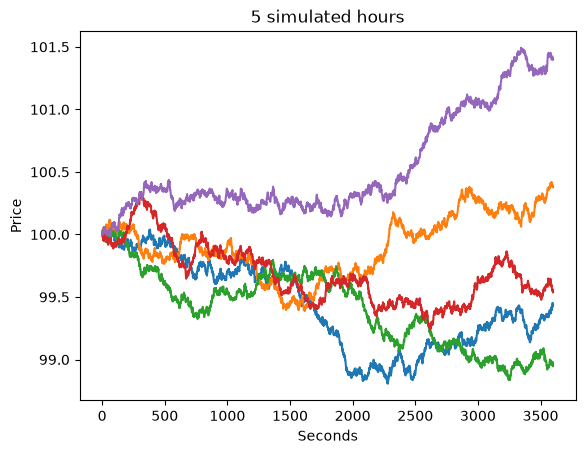

In [1]:
import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt
from src.simulation import simulate_price

rng = np.random.default_rng(42)

for _ in range(5):
    plt.plot(simulate_price(rng))

plt.xlabel("Seconds")
plt.ylabel("Price")
plt.title("5 simulated hours")
plt.show()

0.5776204822605802


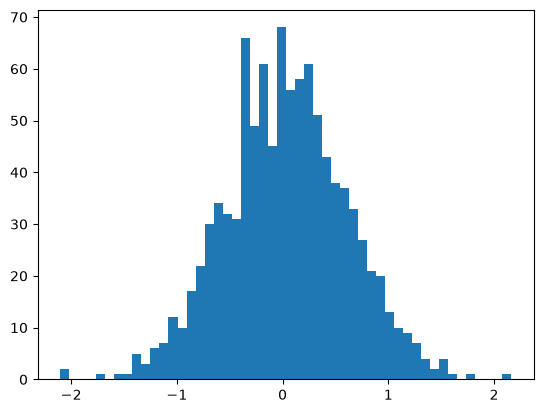

In [2]:
moves = [simulate_price(rng)[-1] - 100 for _ in range(1000)]
print(np.std(moves))
plt.hist(moves, bins=50)
plt.show()

In [3]:
from src.simulation import fill_probability

for d in [0, 0.005, 0.01, 0.02, 0.05]:
    print(d, round(fill_probability(d), 3))

0 0.5
0.005 0.303
0.01 0.184
0.02 0.068
0.05 0.003


In [4]:
rng = np.random.default_rng(42)
p = fill_probability(0.01)          # 0.184

fills = rng.random(3600) < p        # True/False for each of the 3,600 seconds
print(fills[:10])                   # the first 10 seconds
print(fills.sum())                  # how many fills in the hour

[False False False False  True False False False  True False]
682


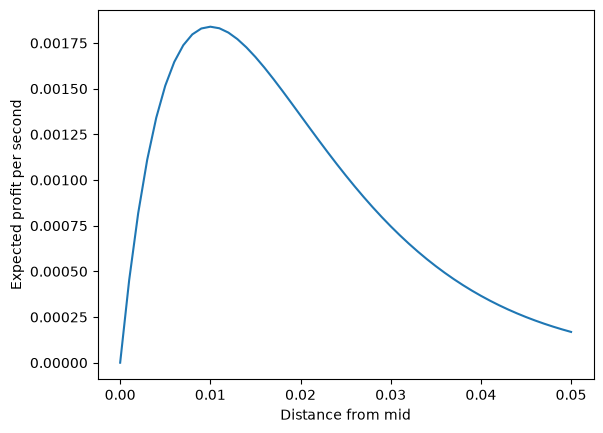

0.01


In [5]:
distances = np.linspace(0, 0.05, 51)
profit = distances * fill_probability(distances)

plt.plot(distances, profit)
plt.xlabel("Distance from mid")
plt.ylabel("Expected profit per second")
plt.show()

print(distances[profit.argmax()])

            mid  inventory         cash        pnl
3595  99.453225         33 -3263.317974  18.638436
3596  99.448949         34 -3362.761198  18.503067
3597  99.443238         34 -3362.761198  18.308881
3598  99.425488         34 -3362.761198  17.705400
3599  99.439449         34 -3362.761198  18.180071


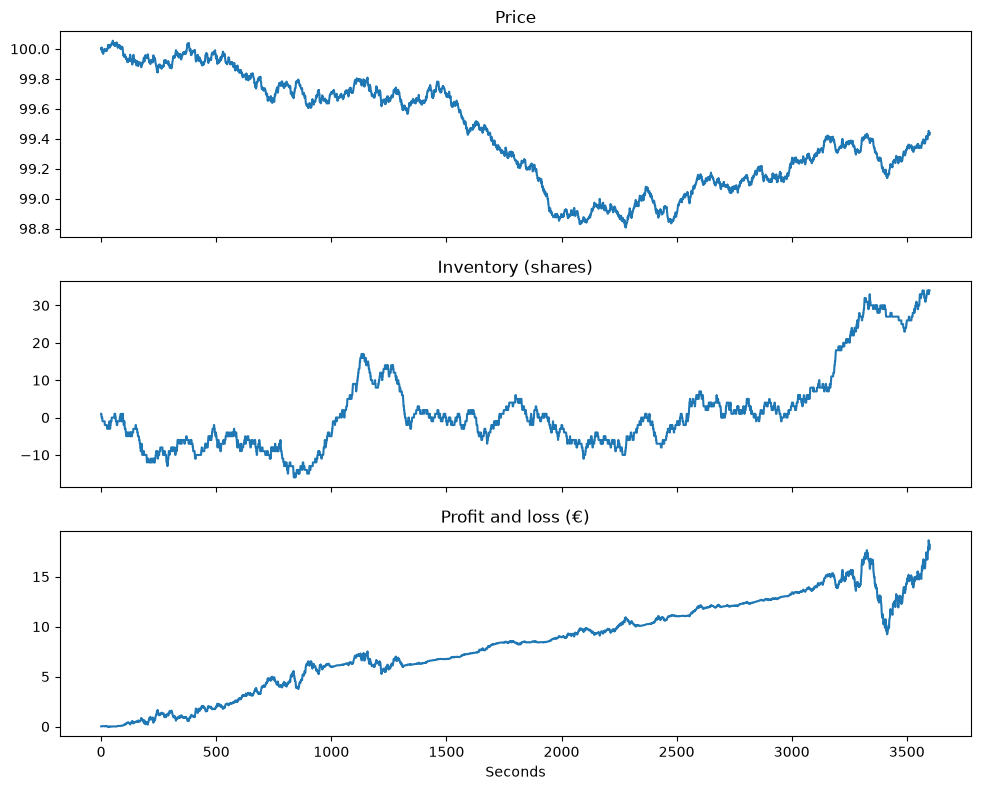

In [6]:
import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt
from src.simulation import simulate_price, run_market_maker

rng = np.random.default_rng(42)
prices = simulate_price(rng)
result = run_market_maker(rng, prices)

print(result.tail())

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
result["mid"].plot(ax=axes[0], title="Price")
result["inventory"].plot(ax=axes[1], title="Inventory (shares)")
result["pnl"].plot(ax=axes[2], title="Profit and loss (€)")
plt.xlabel("Seconds")
plt.tight_layout()
plt.show()

Average PnL per hour: 14.4
Std of PnL: 14.54
Share of losing hours: 0.12
Worst hour: -59.27
Average max inventory: 42.1


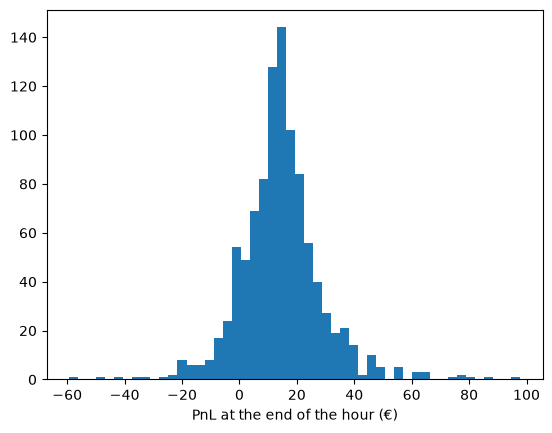

In [7]:
final_pnl = []
max_inventory = []

for _ in range(1000):
    prices = simulate_price(rng)
    result = run_market_maker(rng, prices)
    final_pnl.append(result["pnl"].iloc[-1])
    max_inventory.append(result["inventory"].abs().max())

final_pnl = np.array(final_pnl)

print("Average PnL per hour:", final_pnl.mean().round(2))
print("Std of PnL:", final_pnl.std().round(2))
print("Share of losing hours:", (final_pnl < 0).mean().round(2))
print("Worst hour:", final_pnl.min().round(2))
print("Average max inventory:", np.mean(max_inventory).round(1))

plt.hist(final_pnl, bins=50)
plt.xlabel("PnL at the end of the hour (€)")
plt.show()

In [8]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.simulation import simulate_price, run_market_maker

def evaluate(skew, n_hours=300, seed=1):
    rng = np.random.default_rng(seed)
    pnls, max_inv = [], []
    for _ in range(n_hours):
        prices = simulate_price(rng)
        result = run_market_maker(rng, prices, skew=skew)
        pnls.append(result["pnl"].iloc[-1])
        max_inv.append(result["inventory"].abs().max())
    pnls = np.array(pnls)
    return {
        "skew": skew,
        "Average PnL": pnls.mean(),
        "Std": pnls.std(),
        "Profit / risk": pnls.mean() / pnls.std(),
        "Losing hours": (pnls < 0).mean(),
        "Worst hour": pnls.min(),
        "Avg max inventory": np.mean(max_inv),
    }

skews = [0, 0.0001, 0.0002, 0.0005, 0.001, 0.002]
results = pd.DataFrame([evaluate(s) for s in skews])
print(results.round(4))

     skew  Average PnL      Std  Profit / risk  Losing hours  Worst hour  \
0  0.0000      13.7062  14.1199         0.9707        0.1267    -26.4230   
1  0.0001      13.5415   3.8225         3.5425        0.0000      2.7602   
2  0.0002      13.4785   2.6969         4.9978        0.0000      5.9532   
3  0.0005      13.2770   1.7366         7.6454        0.0000      8.5981   
4  0.0010      13.0390   1.2632        10.3221        0.0000      9.5427   
5  0.0020      12.7196   0.9184        13.8501        0.0000     10.5634   

   Avg max inventory  
0            41.3300  
1            16.8267  
2            12.9933  
3             9.0367  
4             6.7400  
5             4.9767  


In [9]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.simulation import simulate_price, run_market_maker

def evaluate(skew, n_hours=300, seed=1):
    rng = np.random.default_rng(seed)
    pnls, max_inv = [], []
    for _ in range(n_hours):
        prices = simulate_price(rng)
        result = run_market_maker(rng, prices, skew=skew)
        pnls.append(result["pnl"].iloc[-1])
        max_inv.append(result["inventory"].abs().max())
    pnls = np.array(pnls)
    return {
        "skew": skew,
        "Average PnL": pnls.mean(),
        "Std": pnls.std(),
        "Profit / risk": pnls.mean() / pnls.std(),
        "Losing hours": (pnls < 0).mean(),
        "Worst hour": pnls.min(),
        "Avg max inventory": np.mean(max_inv),
    }

skews = [0.002, 0.005, 0.01, 0.02]
results = pd.DataFrame([evaluate(s) for s in skews])
print(results.round(4))

    skew  Average PnL     Std  Profit / risk  Losing hours  Worst hour  \
0  0.002      12.7196  0.9184        13.8501           0.0     10.5634   
1  0.005      11.6611  0.6106        19.0962           0.0      9.6172   
2  0.010       9.3745  0.4804        19.5143           0.0      8.0967   
3  0.020       2.2336  0.3609         6.1887           0.0      1.1902   

   Avg max inventory  
0             4.9767  
1             3.0800  
2             2.0000  
3             1.0000  


In [10]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.simulation import simulate_price, run_market_maker

def evaluate(distance=0.01, skew=0.002, informed_rate=0.0, n_hours=100, seed=1):
    rng = np.random.default_rng(seed)
    pnls = []
    for _ in range(n_hours):
        prices = simulate_price(rng)
        result = run_market_maker(rng, prices, distance=distance, skew=skew,
                                  informed_rate=informed_rate)
        pnls.append(result["pnl"].iloc[-1])
    pnls = np.array(pnls)
    return {
        "informed_rate": informed_rate,
        "distance": distance,
        "Average PnL": pnls.mean(),
        "Std": pnls.std(),
        "Losing hours": (pnls < 0).mean(),
    }

rows = []
for rate in [0, 0.02, 0.05, 0.1]:
    for d in [0.01, 0.02, 0.03, 0.05]:
        rows.append(evaluate(distance=d, informed_rate=rate))

results = pd.DataFrame(rows)
print(results.round(3))

    informed_rate  distance  Average PnL    Std  Losing hours
0            0.00      0.01       12.713  0.946          0.00
1            0.00      0.02        9.674  0.953          0.00
2            0.00      0.03        5.305  0.943          0.00
3            0.00      0.05        1.250  0.941          0.07
4            0.02      0.01       12.400  0.965          0.00
5            0.02      0.02        8.792  1.046          0.00
6            0.02      0.03        3.829  1.103          0.00
7            0.02      0.05       -0.306  1.503          0.59
8            0.05      0.01       11.957  1.016          0.00
9            0.05      0.02        7.553  1.126          0.00
10           0.05      0.03        1.983  1.361          0.08
11           0.05      0.05       -2.427  2.458          0.90
12           0.10      0.01       11.304  1.168          0.00
13           0.10      0.02        6.103  1.305          0.00
14           0.10      0.03       -0.522  1.889          0.62
15      

In [11]:
def evaluate(distance=0.01, skew=0.002, informed_rate=0.0, horizon=60,
             n_hours=100, seed=1):
    rng = np.random.default_rng(seed)
    pnls = []
    for _ in range(n_hours):
        prices = simulate_price(rng)
        result = run_market_maker(rng, prices, distance=distance, skew=skew,
                                  informed_rate=informed_rate, horizon=horizon)
        pnls.append(result["pnl"].iloc[-1])
    pnls = np.array(pnls)
    return {
        "skew": skew,
        "horizon": horizon,
        "informed_rate": informed_rate,
        "Average PnL": pnls.mean(),
        "Std": pnls.std(),
        "Losing hours": (pnls < 0).mean(),
    }

rows = []
for skew in [0, 0.002]:
    for horizon in [5, 60]:
        for rate in [0, 0.1]:
            rows.append(evaluate(skew=skew, horizon=horizon, informed_rate=rate))

results = pd.DataFrame(rows)
print(results.round(3))

    skew  horizon  informed_rate  Average PnL     Std  Losing hours
0  0.000        5            0.0       14.863  15.200          0.13
1  0.000        5            0.1        9.990  17.577          0.24
2  0.000       60            0.0       14.863  15.200          0.13
3  0.000       60            0.1       -4.180  21.972          0.51
4  0.002        5            0.0       12.713   0.946          0.00
5  0.002        5            0.1        9.916   1.051          0.00
6  0.002       60            0.0       12.713   0.946          0.00
7  0.002       60            0.1       11.304   1.168          0.00
